# Notebook 01b: A strict evaluation and the negation autopsy

**Goal.** Notebook 01 found two things: an AUROC of 0.98, and a probe that reads negated translations backwards (AUROC 0.00). Both are strong claims, so I check them again with a stricter protocol.

**A. A fair headline number.** Statements about the same fact (for example *"Krasnodar is in Russia"* and *"Krasnodar is not in Russia"*) always go to the same split. I choose the layer on a **validation** set and use the **test** set only once.

**B. Negation autopsy.** For every fact I have an affirmative and a negated statement with opposite labels. If the probe reads truth, its reading must flip sign when I add *not*. If it reads "these words go together", the reading stays the same and the probe is fooled. I measure this at every layer with cross-fitted scores, so each pair is scored by a probe that never saw that fact.

**C. Sanity checks.** I check the labels of every pair and look at real examples, so the 0.00 cannot be a data bug.

**How to run.** Colab with an A100, about 10 to 15 minutes. It reads `statements.csv` from notebook 01 in Google Drive.

## 0. Configuration

In [1]:
MODEL_ID   = "google/gemma-2-2b-it"
BATCH_SIZE = 32
N_FOLDS    = 5          # cross-fitting folds for the autopsy
ALL_STRIDE = 2          # the 'trained on everything' probe is fitted every N layers
N_BOOT     = 1000
SEED       = 0

In [2]:
import re, json, time, hashlib, pathlib, subprocess
import numpy as np, pandas as pd
from tqdm.auto import tqdm
np.random.seed(SEED)
MODEL_SHORT = MODEL_ID.split("/")[-1]
IN_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in globals() else False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = pathlib.Path("/content/drive/MyDrive/ai-polygraph") / MODEL_SHORT
else:
    OUT = pathlib.Path(globals().get("OUT_OVERRIDE", "outputs")) / MODEL_SHORT
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
assert (OUT / "statements.csv").exists(), f"Run notebook 01 first ({OUT})"
st = pd.read_csv(OUT / "statements.csv")

GOT_DIR = pathlib.Path(globals().get("GOT_DIR", "geometry-of-truth"))
if not GOT_DIR.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/saprmarks/geometry-of-truth.git", str(GOT_DIR)], check=True)
    subprocess.run(["git", "-C", str(GOT_DIR), "checkout", "-q", "5d1c630c44f7e50bda7ad86d601ccadf9abc5ddb"], check=True)

Mounted at /content/drive


## 1. Group statements by fact
`fact_id` links every statement about the same city, Spanish word, number pair, company or subject, across datasets. I draw the train, validation and test splits over facts, never over single sentences. Otherwise the probe could see *"X is in Y"* in training and be tested on *"X is not in Y"*.

In [3]:
def fact_id(s, ds):
    if ds in ("cities", "neg_cities"):
        m = re.match(r"The city of (.+?) is", s);           return "city:" + (m.group(1) if m else s)
    if ds in ("sp_en_trans", "neg_sp_en_trans"):
        m = re.match(r"The Spanish word '(.+?)'", s);       return "sp:" + (m.group(1) if m else s)
    if ds in ("larger_than", "smaller_than"):
        m = re.match(r"(.+?) is (?:larger|smaller) than (.+?)\.", s)
        return "num:" + "|".join(sorted(m.groups())) if m else "num:" + s
    if ds == "counterfact_true_false":
        return "cf:" + " ".join(s.split()[:6])
    if ds == "companies_true_false":          # group every claim about the same company
        m = re.match(r"(.+?) (?:engages|is|operates|has|was|provides|develops|manufactures|offers|specializes|focuses)\b", s)
        return "co:" + (m.group(1) if m else s)
    return ds + ":" + s

st["fact"] = [fact_id(s, d) for s, d in zip(st.statement, st.dataset)]
h = np.array([int(hashlib.md5((f + str(SEED)).encode()).hexdigest(), 16) % 100 for f in st.fact])
st["split3"] = np.where(h < 60, "train", np.where(h < 80, "val", "test"))
st["fold"] = h % N_FOLDS
print(st.groupby("split3").size().to_string())
assert st.groupby("fact").split3.nunique().max() == 1, "A fact appears in more than one split"
assert st.groupby("fact").fold.nunique().max() == 1, "A fact appears in more than one fold"
print("facts per dataset:", st.groupby("dataset").fact.nunique().to_dict())
# Caveat: grouping is by surface keys (city, Spanish word, number pair, company, subject). Semantically
# related claims with different keys (e.g. common_claim) can still fall in different splits.

split3
test     1444
train    4649
val      1603
facts per dataset: {'cities': 500, 'common_claim_true_false': 1000, 'companies_true_false': 201, 'counterfact_true_false': 964, 'larger_than': 1000, 'neg_cities': 500, 'neg_sp_en_trans': 341, 'smaller_than': 1000, 'sp_en_trans': 341}


## 2. Model and activations
Same model and same `assistant` format as notebook 01, at all layers.

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
if IN_COLAB:
    try:
        from google.colab import userdata
        from huggingface_hub import login
        login(token=userdata.get("HF_TOKEN"))
    except Exception as e:
        print("HF login skipped:", e)
tok = AutoTokenizer.from_pretrained(MODEL_ID); tok.padding_side = "left"
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.bfloat16, device_map="cuda",
                                             attn_implementation="eager").eval()
N_LAYERS = model.config.num_hidden_layers; LAYERS = list(range(N_LAYERS + 1))
CHAT_PREFIX = tok.apply_chat_template([{"role": "user", "content": "Tell me one fact."}],
                                      tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def extract(texts, batch_size=BATCH_SIZE):
    acts = np.zeros((len(LAYERS), len(texts), model.config.hidden_size), dtype=np.float32)
    for i in tqdm(range(0, len(texts), batch_size), desc="activations"):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        hs = model(**enc, output_hidden_states=True).hidden_states
        acts[:, i:i + enc.input_ids.shape[0]] = torch.stack([h[:, -1] for h in hs]).float().cpu().numpy()
    return acts

ACTS = extract([CHAT_PREFIX + s for s in st.statement])

ASK_TMPL = "Is the following statement true or false? Answer with exactly one word: True or False.\n\nStatement: "

@torch.no_grad()
def check_ask_tokens(statements, batch_size=BATCH_SIZE):
    # Does the model really answer with the 'True'/'False' tokens we compare? Report top-1 token and probability mass.
    t_id = tok.encode("True", add_special_tokens=False); f_id = tok.encode("False", add_special_tokens=False)
    print("token ids  True:", t_id, " False:", f_id)
    prompts = [tok.apply_chat_template([{"role": "user", "content": ASK_TMPL + s}], tokenize=False,
                                       add_generation_prompt=True) for s in statements]
    top, mass = [], []
    for i in range(0, len(prompts), batch_size):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        pr = model(**enc).logits[:, -1].float().softmax(-1)
        top += [tok.decode([t]) for t in pr.argmax(-1).tolist()]
        mass += (pr[:, t_id[0]] + pr[:, f_id[0]]).cpu().tolist()
    top = pd.Series(top).value_counts(normalize=True)
    print("most likely first answer token:", top.head(5).round(3).to_dict())
    print(f"mean probability on 'True'+'False': {np.mean(mass):.3f}")
    if np.mean(mass) < 0.8:
        print("WARNING: the model often starts its answer with another token; the ask-the-model baseline may be unfair.")
    return top, float(np.mean(mass))

@torch.no_grad()
def ask_model(statements, batch_size=BATCH_SIZE):
    t_id = tok.encode("True", add_special_tokens=False)[0]; f_id = tok.encode("False", add_special_tokens=False)[0]
    prompts = [tok.apply_chat_template([{"role": "user", "content": ASK_TMPL + s}],
               tokenize=False, add_generation_prompt=True) for s in statements]
    out = []
    for i in range(0, len(prompts), batch_size):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        lg = model(**enc).logits[:, -1].float()
        out.append((lg[:, t_id] - lg[:, f_id]).cpu().numpy())
    return np.concatenate(out)

config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

activations:   0%|          | 0/241 [00:00<?, ?it/s]

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score

def fit(X, y, C=0.1):
    sc = StandardScaler().fit(X)
    return sc, LogisticRegression(C=C, max_iter=2000, tol=1e-3).fit(sc.transform(X), y)

def score(p, X):
    return p[1].decision_function(p[0].transform(X))

def boot_ci(y, s, groups, n=N_BOOT, seed=SEED):
    # 95% CI for AUROC, resampling whole FACTS (all statements about one fact move together)
    rng = np.random.default_rng(seed); y, s, groups = np.asarray(y), np.asarray(s), np.asarray(groups)
    uniq, inv = np.unique(groups, return_inverse=True)
    members = [np.where(inv == k)[0] for k in range(len(uniq))]
    vals = []
    for _ in range(n):
        idx = np.concatenate([members[k] for k in rng.integers(0, len(uniq), len(uniq))])
        if 0 < y[idx].sum() < len(idx):
            vals.append(roc_auc_score(y[idx], s[idx]))
    return np.percentile(vals, [2.5, 97.5])

y = st.label.values

## A. The headline number
I train a probe on the **train** facts at every layer, pick the layer on the **validation** facts, and evaluate it **once** on the **test** facts. The 95% confidence intervals resample facts, not sentences.

In [6]:
m_tr, m_va, m_te = (st.split3 == "train").values, (st.split3 == "val").values, (st.split3 == "test").values
val_auc = {}
for L in tqdm(LAYERS, desc="layer selection"):
    p = fit(ACTS[L][m_tr], y[m_tr])
    val_auc[L] = roc_auc_score(y[m_va], score(p, ACTS[L][m_va]))
SEL_LAYER = max(val_auc, key=val_auc.get)
p_final = fit(ACTS[SEL_LAYER][m_tr | m_va], y[m_tr | m_va])          # refit on train+val, test once
s_te = score(p_final, ACTS[SEL_LAYER][m_te])
g_te = st.fact.values[m_te]
TEST_AUC = roc_auc_score(y[m_te], s_te); TEST_CI = boot_ci(y[m_te], s_te, g_te)
TEST_ACC = accuracy_score(y[m_te], (s_te > 0).astype(int))
ASK_TOP, ASK_MASS = check_ask_tokens(st.statement[m_te].sample(200, random_state=SEED).tolist())
ask_te = ask_model(st.statement[m_te].tolist())
ASK_AUC = roc_auc_score(y[m_te], ask_te); ASK_CI = boot_ci(y[m_te], ask_te, g_te)
print(f"Layer chosen on validation: {SEL_LAYER}")
print(f"Test set: {m_te.sum()} statements about {len(set(g_te))} distinct facts (CIs resample facts)")
print(f"TEST  polygraph AUROC {TEST_AUC:.3f} [{TEST_CI[0]:.3f}, {TEST_CI[1]:.3f}]  acc {TEST_ACC:.3f}")
print(f"TEST  ask-the-model AUROC {ASK_AUC:.3f} [{ASK_CI[0]:.3f}, {ASK_CI[1]:.3f}]")
per_ds = pd.DataFrame([{"dataset": d, "n": int(m.sum()),
                        "polygraph_auroc": roc_auc_score(y[m_te][m], s_te[m]),
                        "ask_model_auroc": roc_auc_score(y[m_te][m], ask_te[m])}
                       for d in st.dataset.unique()
                       if (m := (st.dataset[m_te] == d).values).sum() > 4 and len(np.unique(y[m_te][m])) == 2]).round(3)
display(per_ds)

layer selection:   0%|          | 0/27 [00:00<?, ?it/s]

token ids  True: [5036]  False: [8393]
most likely first answer token: {'False': 0.52, 'True': 0.48}
mean probability on 'True'+'False': 1.000
Layer chosen on validation: 14
Test set: 1444 statements about 774 distinct facts (CIs resample facts)
TEST  polygraph AUROC 0.981 [0.975, 0.987]  acc 0.928
TEST  ask-the-model AUROC 0.957 [0.946, 0.966]


,dataset,n,polygraph_auroc,ask_model_auroc
0,cities,184,1.000,1.000
1,neg_cities,184,1.000,1.000
2,sp_en_trans,79,0.999,1.000
3,neg_sp_en_trans,79,1.000,1.000
4,larger_than,172,1.000,1.000
5,smaller_than,172,1.000,0.967
6,companies_true_false,166,0.978,0.944
7,counterfact_true_false,220,0.873,0.879
8,common_claim_true_false,188,0.876,0.883


**Result.** Layer 14 is chosen on validation, the same layer as in notebook 01. On the test set the probe scores **AUROC 0.981 [0.975, 0.987]** (accuracy 0.928). Asking Gemma "true or false?" scores 0.957 [0.946, 0.966]. This is the number I report everywhere.

I do not read this as "the hidden states know more than Gemma says". Dataset by dataset (table below) the two are very close: the probe is better on 2 datasets, asking is better on 2, and they tie on 5 (mean 0.970 vs 0.964). The pooled gap comes mostly from the probe being better calibrated across datasets, and the probe was trained on these 9 datasets while asking is zero-shot. What matters for the rest of the project is that the probe is **as good as asking**, and that it can read a claim without asking Gemma anything.

## B. Negation autopsy
Each pair is the same sentence with and without *not*: *"The city of X is in C."* and *"The city of X is not in C."*, or *"The Spanish word 'w' means 'm'."* and *"The Spanish word 'w' does not mean 'm'."*

I compare two probes, both cross-fitted over facts:
- **Same-domain affirmative probe**: trained only on affirmative statements of that domain.
- **Full polygraph**: trained on all nine datasets, negations included.

Main metrics, per fact:
- **AUROC on the negated statements** (below 0.5 means the probe reads them backwards).
- **Both correct**: share of facts where the affirmative and the negated statement are both classified correctly.
- **Flip rate**: share of pairs whose reading changes sign.

In [7]:
def make_pairs():
    rows = []
    for aff_ds, neg_ds, f in [("cities", "neg_cities", lambda s: s.replace(" is not in ", " is in ")),
                              ("sp_en_trans", "neg_sp_en_trans", lambda s: s.replace(" does not mean ", " means "))]:
        a = st[st.dataset == aff_ds].reset_index()
        n = st[st.dataset == neg_ds].reset_index()
        n["aff_text"] = n.statement.map(f)
        mm = n.merge(a, left_on="aff_text", right_on="statement", suffixes=("_neg", "_aff"))
        for r in mm.itertuples():
            rows.append({"domain": "cities" if aff_ds == "cities" else "translations",
                         "i_aff": r.index_aff, "i_neg": r.index_neg, "aff": r.statement_aff, "neg": r.statement_neg,
                         "y_aff": r.label_aff, "y_neg": r.label_neg, "fact": r.fact_aff, "fact_neg": r.fact_neg,
                         "fold": r.fold_aff, "fold_neg": r.fold_neg})
    return pd.DataFrame(rows)

pairs = make_pairs()
bad = pairs[pairs.y_aff == pairs.y_neg]
print(pairs.domain.value_counts().to_string())
print("pairs whose labels do NOT flip with 'not' (should be 0):", len(bad))
# hard checks: stop here if the pairs are not what we think they are
assert len(pairs) > 0, "No negation pairs found"
assert set(pairs.domain) == {"cities", "translations"}, pairs.domain.unique()
assert pairs.domain.value_counts().min() >= 30, "Too few pairs in a domain"
assert (pairs.y_aff != pairs.y_neg).all(), "Some pairs do not have opposite labels"
assert (pairs.fact == pairs.fact_neg).all() and (pairs.fold == pairs.fold_neg).all(), "Pair members are not the same fact"
assert not pairs.duplicated(["domain", "i_aff", "i_neg"]).any(), "Duplicate pairs"
assert not pairs.duplicated(["domain", "i_neg"]).any(), "A negated statement is paired twice"
assert st.groupby("fact").split3.nunique().max() == 1, "A fact leaks across train/val/test"
print("all pair checks passed")
display(pairs.sample(6, random_state=SEED)[["domain", "aff", "y_aff", "neg", "y_neg"]])

domain
cities          1000
translations     348
pairs whose labels do NOT flip with 'not' (should be 0): 0
all pair checks passed


,domain,aff,y_aff,neg,y_neg
839,cities,The city of Puning is in India.,0,The city of Puning is not in India.,1
184,cities,The city of Fes is in Morocco.,1,The city of Fes is not in Morocco.,0
862,cities,The city of Putian is in Vietnam.,0,The city of Putian is not in Vietnam.,1
742,cities,The city of Changwon is in Indonesia.,0,The city of Changwon is not in Indonesia.,1
530,cities,The city of Nanchong is in Nigeria.,0,The city of Nanchong is not in Nigeria.,1
142,cities,The city of Guangyuan is in China.,1,The city of Guangyuan is not in China.,0


In [8]:
AFF_DS = {"cities": "cities", "translations": "sp_en_trans"}
auto = []
all_layers = sorted(set(LAYERS[::ALL_STRIDE]) | {SEL_LAYER})
for L in tqdm(LAYERS, desc="autopsy"):
    X = ACTS[L]
    for kind in (["same-domain affirmative", "full polygraph"] if L in all_layers else ["same-domain affirmative"]):
        for dom, g in pairs.groupby("domain"):
            s_aff, s_neg = np.zeros(len(g)), np.zeros(len(g))
            for k in range(N_FOLDS):
                test_rows = (g.fold == k).values
                if not test_rows.any():
                    continue
                if kind == "same-domain affirmative":
                    m = ((st.dataset == AFF_DS[dom]) & (st.fold != k)).values
                else:
                    m = (st.fold != k).values
                p = fit(X[m], y[m])
                s_aff[test_rows] = score(p, X[g.i_aff.values[test_rows]])
                s_neg[test_rows] = score(p, X[g.i_neg.values[test_rows]])
            ok_aff = (s_aff > 0) == (g.y_aff.values == 1); ok_neg = (s_neg > 0) == (g.y_neg.values == 1)
            auto.append({"layer": L, "probe": kind, "domain": dom,
                         "both_correct": np.mean(ok_aff & ok_neg), "neg_correct": np.mean(ok_neg),
                         "flip_rate": np.mean(np.sign(s_aff) != np.sign(s_neg)),
                         "corr": np.corrcoef(s_aff, s_neg)[0, 1],
                         "auroc_aff": roc_auc_score(g.y_aff, s_aff), "auroc_neg": roc_auc_score(g.y_neg, s_neg),
                         "s_aff": s_aff, "s_neg": s_neg})
auto = pd.DataFrame(auto)
# 95% CIs at the polygraph layer (one pair = one fact, so resampling pairs = resampling facts)
rng = np.random.default_rng(SEED)
for i in auto.index[auto.layer == SEL_LAYER]:
    r = auto.loc[i]; g = pairs[pairs.domain == r.domain]
    yn = g.y_neg.values; ya = g.y_aff.values
    bs_auc, bs_both = [], []
    for _ in range(N_BOOT):
        k = rng.integers(0, len(g), len(g))
        if 0 < yn[k].sum() < len(k):
            bs_auc.append(roc_auc_score(yn[k], r.s_neg[k]))
        bs_both.append(np.mean(((r.s_aff[k] > 0) == (ya[k] == 1)) & ((r.s_neg[k] > 0) == (yn[k] == 1))))
    auto.loc[i, ["auroc_neg_lo", "auroc_neg_hi"]] = np.percentile(bs_auc, [2.5, 97.5])
    auto.loc[i, ["both_lo", "both_hi"]] = np.percentile(bs_both, [2.5, 97.5])
display(auto[auto.layer == SEL_LAYER].drop(columns=["s_aff", "s_neg"]).round(3))

ask_neg = {dom: roc_auc_score(g.y_neg, ask_model(g.neg.tolist())) for dom, g in pairs.groupby("domain")}
print("Ask-the-model AUROC on the negated statements:", {k: round(v, 3) for k, v in ask_neg.items()})

autopsy:   0%|          | 0/27 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


,layer,probe,domain,both_correct,neg_correct,flip_rate,corr,auroc_aff,auroc_neg,auroc_neg_lo,auroc_neg_hi,both_lo,both_hi
42,14,same-domain affirmative,cities,0.768,0.771,0.770,-0.672,0.999,0.930,0.913,0.945,0.742,0.793
43,14,same-domain affirmative,translations,0.276,0.276,0.279,0.889,1.000,0.011,0.003,0.022,0.227,0.325
44,14,full polygraph,cities,0.994,0.998,0.996,-0.964,1.000,1.000,1.000,1.000,0.989,0.998
45,14,full polygraph,translations,0.980,0.986,0.989,-0.913,0.999,0.999,0.996,1.000,0.963,0.994


Ask-the-model AUROC on the negated statements: {'cities': np.float64(1.0), 'translations': np.float64(0.997)}


**Result.** The failure from notebook 01 is real. The same-domain affirmative probe scores **AUROC 0.011 [0.003, 0.022]** on negated translations at layer 14: it reads almost every one of them backwards. Only 28% of translation pairs are both correct. For cities the same probe does much better (0.93).

The full polygraph, trained with negations, fixes it: AUROC 0.999 on negated translations and 98% of pairs both correct. Asking Gemma also handles negations well (0.997), so the model itself understands *not*. The problem was what the probe learned, not what the model knows.

## Figures

In [9]:
import matplotlib.pyplot as plt
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9b9a94"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "font.size": 12,
    "axes.titlesize": 15, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False, "text.color": INK})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight"); plt.show()
DCOL = {"cities": BLUE, "translations": ORANGE}

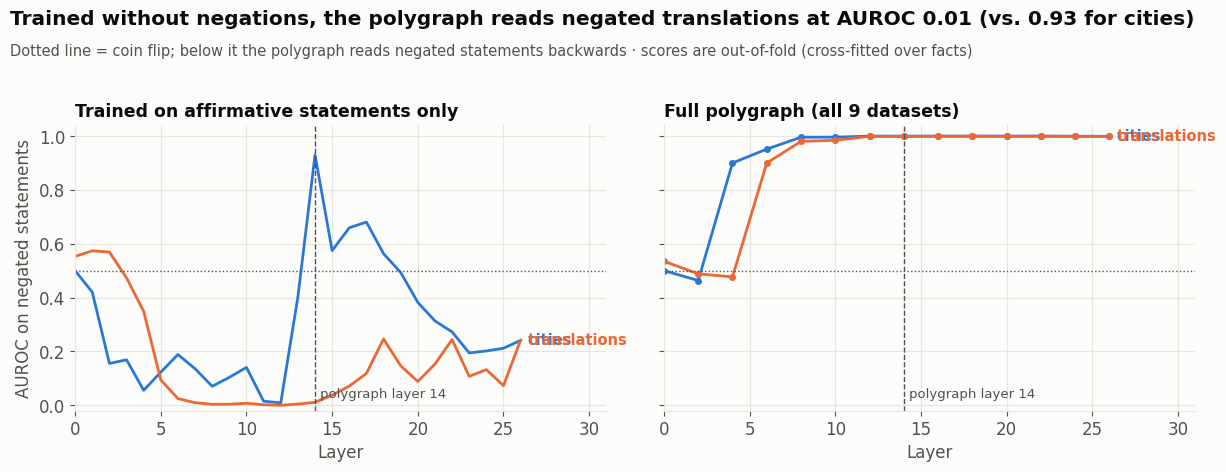

In [10]:
# Figure 6: Can the polygraph read negated statements? (layer by layer)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
for ax, kind in zip(axes, ["same-domain affirmative", "full polygraph"]):
    for dom, c in DCOL.items():
        d = auto[(auto.probe == kind) & (auto.domain == dom)].sort_values("layer")
        ax.plot(d.layer, d.auroc_neg, color=c, lw=2, marker="o" if kind == "full polygraph" else None, ms=4)
        ax.text(d.layer.iloc[-1] + 0.4, d.auroc_neg.iloc[-1], dom, color=c, fontsize=10.5, va="center", weight="semibold")
    ax.axhline(0.5, color=INK2, lw=1, ls=":")
    ax.axvline(SEL_LAYER, color=INK2, lw=1, ls="--")
    ax.text(SEL_LAYER + 0.3, 0.03, f"polygraph layer {SEL_LAYER}", fontsize=9.5, color=INK2)
    ax.set_ylim(-0.02, 1.04); ax.set_xlim(0, max(LAYERS) + 5); ax.set_xlabel("Layer")
    ax.set_title("Trained on affirmative statements only" if kind.startswith("same") else "Full polygraph (all 9 datasets)",
                 fontsize=12.5)
axes[0].set_ylabel("AUROC on negated statements")
r = auto[(auto.layer == SEL_LAYER) & (auto.probe == "same-domain affirmative")].set_index("domain")
fig.text(0.01, 0.885, "Dotted line = coin flip; below it the polygraph reads negated statements backwards · "
         "scores are out-of-fold (cross-fitted over facts)", fontsize=10.5, color=INK2)
worse, better = ("translations", "cities") if r.loc["translations", "auroc_neg"] < r.loc["cities", "auroc_neg"] else ("cities", "translations")
fig.suptitle(f"Trained without negations, the polygraph reads negated {worse} at AUROC {r.loc[worse, 'auroc_neg']:.2f} "
             f"(vs. {r.loc[better, 'auroc_neg']:.2f} for {better})", x=0.01, ha="left", fontsize=14.5, weight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.9))
save(fig, "fig6_negation_autopsy")

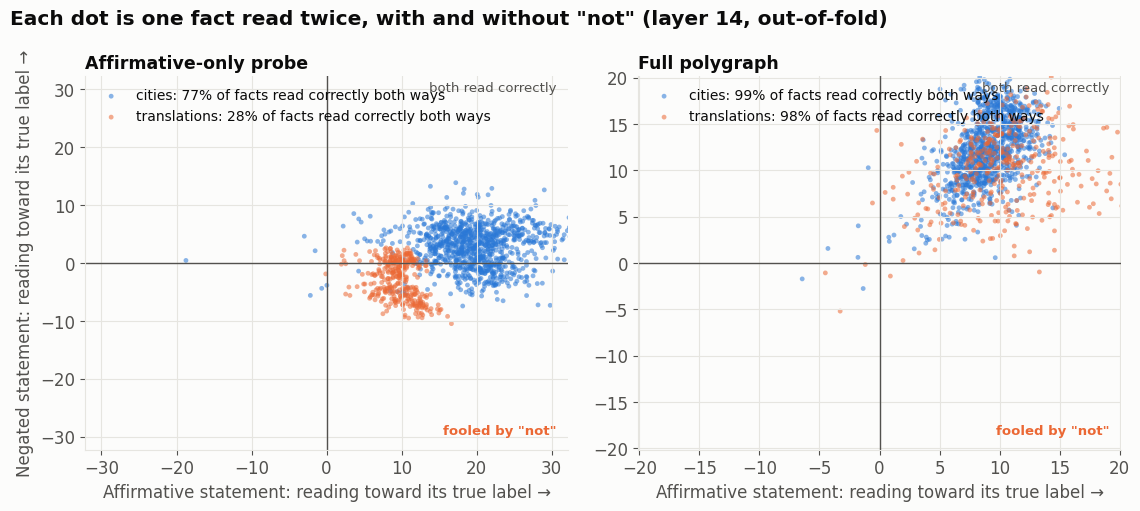

In [11]:
# Figure 7: Every pair at the polygraph layer
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2))
for ax, kind in zip(axes, ["same-domain affirmative", "full polygraph"]):
    lim = 0
    for dom, c in DCOL.items():
        row = auto[(auto.layer == SEL_LAYER) & (auto.probe == kind) & (auto.domain == dom)]
        if not len(row): continue
        row = row.iloc[0]; g = pairs[pairs.domain == dom]
        sign = np.where(g.y_aff.values == 1, 1, -1)       # orient: x>0 means the affirmative is read correctly
        xa, xn = row.s_aff * sign, row.s_neg * -sign       # y>0 means the negated statement is read correctly
        ax.scatter(xa, xn, s=12, alpha=0.55, color=c, edgecolor="none", label=f"{dom}: {row.both_correct*100:.0f}% of facts read correctly both ways")
        lim = max(lim, np.percentile(np.abs(np.r_[xa, xn]), 98))
    lim = lim * 1.1 or 1
    ax.axhline(0, color=INK2, lw=1); ax.axvline(0, color=INK2, lw=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.text(lim * 0.95, lim * 0.92, "both read correctly", ha="right", fontsize=9.5, color=INK2)
    ax.text(lim * 0.95, -lim * 0.92, "fooled by \"not\"", ha="right", fontsize=9.5, color=ORANGE, weight="semibold")
    ax.set_xlabel("Affirmative statement: reading toward its true label →")
    ax.set_title("Affirmative-only probe" if kind.startswith("same") else "Full polygraph", fontsize=12.5)
    ax.legend(loc="upper left", fontsize=10)
axes[0].set_ylabel("Negated statement: reading toward its true label →")
fig.suptitle(f"Each dot is one fact read twice, with and without \"not\" (layer {SEL_LAYER}, out-of-fold)",
             x=0.01, ha="left", fontsize=14.5, weight="semibold")
fig.tight_layout()
save(fig, "fig7_pairs")

## C. Look at real pairs (sanity check)

In [12]:
row = auto[(auto.layer == SEL_LAYER) & (auto.probe == "same-domain affirmative") & (auto.domain == "translations")].iloc[0]
g = pairs[pairs.domain == "translations"].assign(read_aff=row.s_aff, read_neg=row.s_neg)
show = g.assign(verdict_neg=np.where(g.read_neg > 0, "reads TRUE", "reads FALSE"))[
    ["aff", "y_aff", "read_aff", "neg", "y_neg", "read_neg", "verdict_neg"]]
display(show.head(10).round(2))

,aff,y_aff,read_aff,neg,y_neg,read_neg,verdict_neg
1000,The Spanish word 'rojo' means 'red'.,1,9.84,The Spanish word 'rojo' does not mean 'red'.,0,-1.00,reads FALSE
1001,The Spanish word 'mercado' means 'market'.,1,10.47,The Spanish word 'mercado' does not mean 'mark...,0,-0.59,reads FALSE
1002,The Spanish word 'fuego' means 'fire'.,1,8.75,The Spanish word 'fuego' does not mean 'fire'.,0,1.77,reads TRUE
1003,The Spanish word 'lista' means 'list'.,1,9.25,The Spanish word 'lista' does not mean 'list'.,0,-1.36,reads FALSE
1004,The Spanish word 'gato' means 'cat'.,1,10.66,The Spanish word 'gato' does not mean 'cat'.,0,-1.40,reads FALSE
1005,The Spanish word 'esperanza' means 'hope'.,1,10.63,The Spanish word 'esperanza' does not mean 'ho...,0,2.87,reads TRUE
1006,The Spanish word 'jugar' means 'to play'.,1,10.14,The Spanish word 'jugar' does not mean 'to play'.,0,-0.39,reads FALSE
1007,The Spanish word 'olor' means 'smell'.,1,8.94,The Spanish word 'olor' does not mean 'smell'.,0,1.57,reads TRUE
1008,The Spanish word 'esquina' means 'corner'.,1,8.81,The Spanish word 'esquina' does not mean 'corn...,0,1.28,reads TRUE
1009,The Spanish word 'huevo' means 'egg'.,1,9.38,The Spanish word 'huevo' does not mean 'egg'.,0,2.29,reads TRUE


The table shows real translation pairs. The affirmative-only probe reads the true affirmative sentences at about +9 to +10. For the false negated sentences it should give a clearly negative reading, but it stays close to zero (for example -1.00 for "'rojo' does not mean 'red'") and is sometimes positive (+1.77 for 'fuego', +2.87 for 'esperanza'). The word *not* barely moves it. The labels are correct (all pair checks passed), so this is not a data bug.

In [13]:
auto.drop(columns=["s_aff", "s_neg"]).to_csv(OUT / "results_autopsy.csv", index=False)
per_ds.to_csv(OUT / "results_test_per_dataset.csv", index=False)
at = auto[auto.layer == SEL_LAYER].drop(columns=["s_aff", "s_neg"])
summary = {
    "model": MODEL_ID, "layer_selected_on_validation": SEL_LAYER,
    "test_polygraph_auroc": round(TEST_AUC, 3), "test_polygraph_ci": [round(x, 3) for x in TEST_CI],
    "test_polygraph_acc": round(TEST_ACC, 3),
    "test_ask_model_auroc": round(ASK_AUC, 3), "test_ask_model_ci": [round(x, 3) for x in ASK_CI],
    "ask_model_true_false_prob_mass": round(ASK_MASS, 3), "ask_model_top_tokens": ASK_TOP.head(3).round(3).to_dict(),
    "n_test": int(m_te.sum()), "pairs": pairs.domain.value_counts().to_dict(), "pairs_with_bad_labels": int(len(bad)),
    "autopsy_at_layer": at.round(3).to_dict(orient="records"),
    "ask_model_auroc_on_negated": {k: round(v, 3) for k, v in ask_neg.items()},
}
(OUT / "summary01b.json").write_text(json.dumps(summary, indent=2, default=float))
print("=" * 20, "SUMMARY", "=" * 20)
print(json.dumps(summary, indent=2, default=float))

==================== SUMMARY ====================
{
  "model": "google/gemma-2-2b-it",
  "layer_selected_on_validation": 14,
  "test_polygraph_auroc": 0.981,
  "test_polygraph_ci": [
    0.975,
    0.987
  ],
  "test_polygraph_acc": 0.928,
  "test_ask_model_auroc": 0.957,
  "test_ask_model_ci": [
    0.946,
    0.966
  ],
  "ask_model_true_false_prob_mass": 1.0,
  "ask_model_top_tokens": {
    "False": 0.52,
    "True": 0.48
  },
  "n_test": 1444,
  "pairs": {
    "cities": 1000,
    "translations": 348
  },
  "pairs_with_bad_labels": 0,
  "autopsy_at_layer": [
    {
      "layer": 14,
      "probe": "same-domain affirmative",
      "domain": "cities",
      "both_correct": 0.768,
      "neg_correct": 0.771,
      "flip_rate": 0.77,
      "corr": -0.672,
      "auroc_aff": 0.999,
      "auroc_neg": 0.93,
      "auroc_neg_lo": 0.913,
      "auroc_neg_hi": 0.945,
      "both_lo": 0.742,
      "both_hi": 0.793
    },
    {
      "layer": 14,
      "probe": "same-domain affirmative",
     

## Summary
- With fact-grouped splits and the layer chosen on validation, the polygraph scores AUROC **0.981 [0.975, 0.987]** on test. Asking Gemma scores 0.957 pooled, and dataset by dataset the two are about equal.
- A probe trained without negations reads negated translations backwards (AUROC 0.01). Including negations in training fixes it.
- Lesson: a high AUROC on one kind of sentence does not prove the probe reads truth. It needs counterexamples.

**Limitations.** The negation test covers two domains only (cities and translations). Other kinds of shortcuts may exist that I did not test.